# Pandas and Spark performance benchmark

Run `python -m spark.benchmark` from the project root to regenerate the measurements. The benchmark uses two sizes of the same LO2v2 sample and compares Pandas with Spark local mode using two execution threads. Both paths read the same CSVs, build reproducible windows, apply the same scaler, and return all results to the driver. Every Spark preprocessing result is checked against Pandas. JVM startup is excluded after a small warm-up.

Wall time is measured twice per configuration except for cache fill. CPU usage is an estimated number of cores used, based on sampled process-tree CPU times. Memory is peak sampled aggregate RSS, which can count shared pages more than once. Spark and Pandas share the benchmark driver, so the Spark JVM can contribute idle memory during Pandas timings.

CPU usage is omitted for actions shorter than the 0.2-second sampling interval.

,method,runs,partitions,seconds,items_per_second,cpu_cores_equivalent,peak_tree_rss_mib,speedup_vs_pandas
0,Pandas,2,0,0.869,962.136,1.239,735.479,1.000
1,Pandas,10,0,4.308,978.358,1.833,1389.701,1.000
2,Spark,2,2,14.385,63.876,4.128,1260.152,0.060
3,Spark,2,4,7.278,114.633,3.450,1345.648,0.119
4,Spark,10,2,14.428,291.922,2.593,1406.469,0.299
5,Spark,10,4,13.411,316.876,2.444,1546.986,0.321


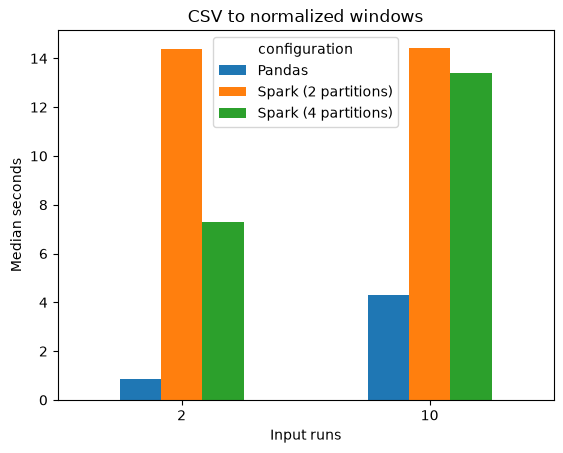

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

raw = pd.read_csv(root / "results/spark_benchmark.csv")
metrics = ["seconds", "items_per_second", "cpu_cores_equivalent", "peak_tree_rss_mib"]
summary = raw.groupby(["stage", "method", "runs", "partitions"])[metrics].median()
preprocessing = summary.loc["preprocess"].reset_index()
reference = preprocessing.loc[preprocessing.method.eq("Pandas")].set_index("runs").seconds
preprocessing["speedup_vs_pandas"] = preprocessing.runs.map(reference) / preprocessing.seconds
display(preprocessing.round(3))

preprocessing["configuration"] = preprocessing.method.where(
    preprocessing.partitions.eq(0),
    preprocessing.method + " (" + preprocessing.partitions.astype(str) + " partitions)",
)
ax = preprocessing.pivot(index="runs", columns="configuration", values="seconds").plot.bar(rot=0)
ax.set(xlabel="Input runs", ylabel="Median seconds", title="CSV to normalized windows")
plt.show()

## Cache reuse and batch inference

Reuse timings materialize the same feature table before and after caching. Cache fill is reported separately. Inference compares in-memory PyTorch with Spark scoring cached input in Python workers. Spark timing includes scheduling, Arrow transfer and collecting predictions to the driver. The same model and 834 windows are used, and the benchmark verifies scores and alert decisions.

The experiment uses one Windows host. Multi-worker scale-out, HDFS throughput, and cross-host fault tolerance require a live cluster.

seconds  items_per_second  \
stage     method           runs partitions                              
reuse     Spark cache fill 10   4            2.1428      1.963323e+03   
          Spark cached     10   4            2.0326      2.070461e+03   
          Spark uncached   10   4            3.9599      1.383560e+03   
inference Central PyTorch  2    0            0.0008      1.032299e+06   
          Spark PyTorch    2    4           13.8551      6.030480e+01   

                                            cpu_cores_equivalent  \
stage     method           runs partitions                         
reuse     Spark cache fill 10   4                         2.5594   
          Spark cached     10   4                         2.0670   
          Spark uncached   10   4                         2.3222   
inference Central PyTorch  2    0                            NaN   
          Spark PyTorch    2    4                         1.9058   

                                            peak_tree_rss_mib  
stage     method           runs partitions                     
reuse     Spark cache fill 10   4                   1561.5820  
          Spark cached     10   4                   1562.1191  
          Spark uncached   10   4                   1556.1641  
inference Central PyTorch  2    0                   1912.1699  
          Spark PyTorch    2    4                   2294.7227

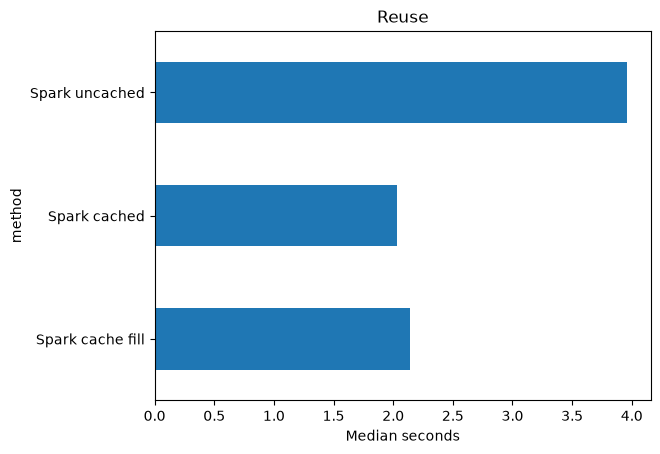

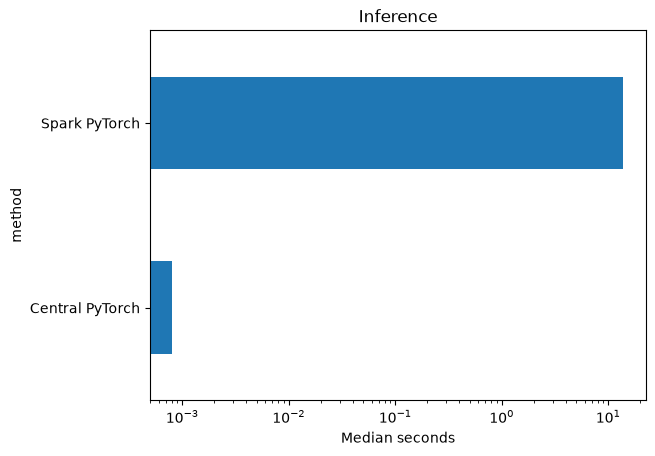

In [2]:
display(summary.loc[["reuse", "inference"]].round(4))
for stage in ("reuse", "inference"):
    medians = summary.loc[stage].reset_index().set_index("method")
    ax = medians.seconds.plot.barh(logx=(stage == "inference"))
    ax.set(xlabel="Median seconds", title=stage.capitalize())
    plt.show()

## HDFS and two Spark workers

The Docker lab compares the same HDFS-backed workload in local mode and standalone mode. Both use two Spark cores and four shuffle partitions. The standalone driver verifies Parquet writes by reading them back after timing. HDFS fsck confirms two copies of every input block on separate DataNode containers. Both Spark workers report inference results in every standalone trial. The containers share one physical host, so these timings apply to the local lab.

In [3]:
import json

lab = json.loads((root / "results/hdfs_spark_validation.json").read_text())
assert lab["hdfs"]["blocks"] == 70 and lab["hdfs"]["replication"] == 2
assert lab["verified_windows"] == 4207 and lab["verified_predictions"] == 834
display(pd.DataFrame(lab["summary"]).round(3))

,runs,master,preprocessing_median_seconds,inference_median_seconds
0,2,local[2],15.466,4.516
1,2,spark://master:7077,21.017,3.286
2,10,local[2],22.720,0.711
3,10,spark://master:7077,16.535,0.580
